In [ ]:
import os
import pandas as pd
from scipy.stats import zscore
import numpy as np
from pandas import DataFrame
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Paths are relative to the project folder: inputs in data/, files written by
# earlier notebooks in results/, figures in figures/.
DATA_DIR = 'data'
RESULTS_DIR = 'results'
FIGURE_DIR = 'figures'

# Input files
CELL_LINE_PREDICTIONS = f'{DATA_DIR}/cell_line_predicitons.csv'
os.makedirs(FIGURE_DIR, exist_ok=True)

In [105]:
df = pd.read_csv(CELL_LINE_PREDICTIONS, index_col=0)

In [106]:
select_cellline = df[['KASUMI1', 'THP1']]
select_cellline['Diff'] = select_cellline['KASUMI1'] - select_cellline['THP1']
select_cellline = select_cellline.sort_values('Diff')

kasumi_cand = select_cellline.head(15)
thp1_cand = select_cellline.tail(15)
thp1_cand['Diff'] = thp1_cand['Diff']*-1

/var/folders/dx/q8czrrps0h71z5jsy2wrs1rr0000gp/T/ipykernel_83455/3533562136.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  select_cellline['Diff'] = select_cellline['KASUMI1'] - select_cellline['THP1']
/var/folders/dx/q8czrrps0h71z5jsy2wrs1rr0000gp/T/ipykernel_83455/3533562136.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  thp1_cand['Diff'] = thp1_cand['Diff']*-1


In [108]:
zdf = DataFrame(zscore(df,axis=1), index=[df.index], columns= df.columns)
select_celllinez = zdf[['KASUMI1', 'THP1']]
select_celllinez['Diff'] = select_celllinez['KASUMI1'] - select_celllinez['THP1']
select_celllinez = select_celllinez.sort_values('Diff')

array = np.array(np.abs(select_celllinez.Diff)*-1)
order = array.argsort()
ranks = order.argsort()
select_celllinez['Rank'] = ranks

/var/folders/dx/q8czrrps0h71z5jsy2wrs1rr0000gp/T/ipykernel_83455/289395028.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  select_celllinez['Diff'] = select_celllinez['KASUMI1'] - select_celllinez['THP1']


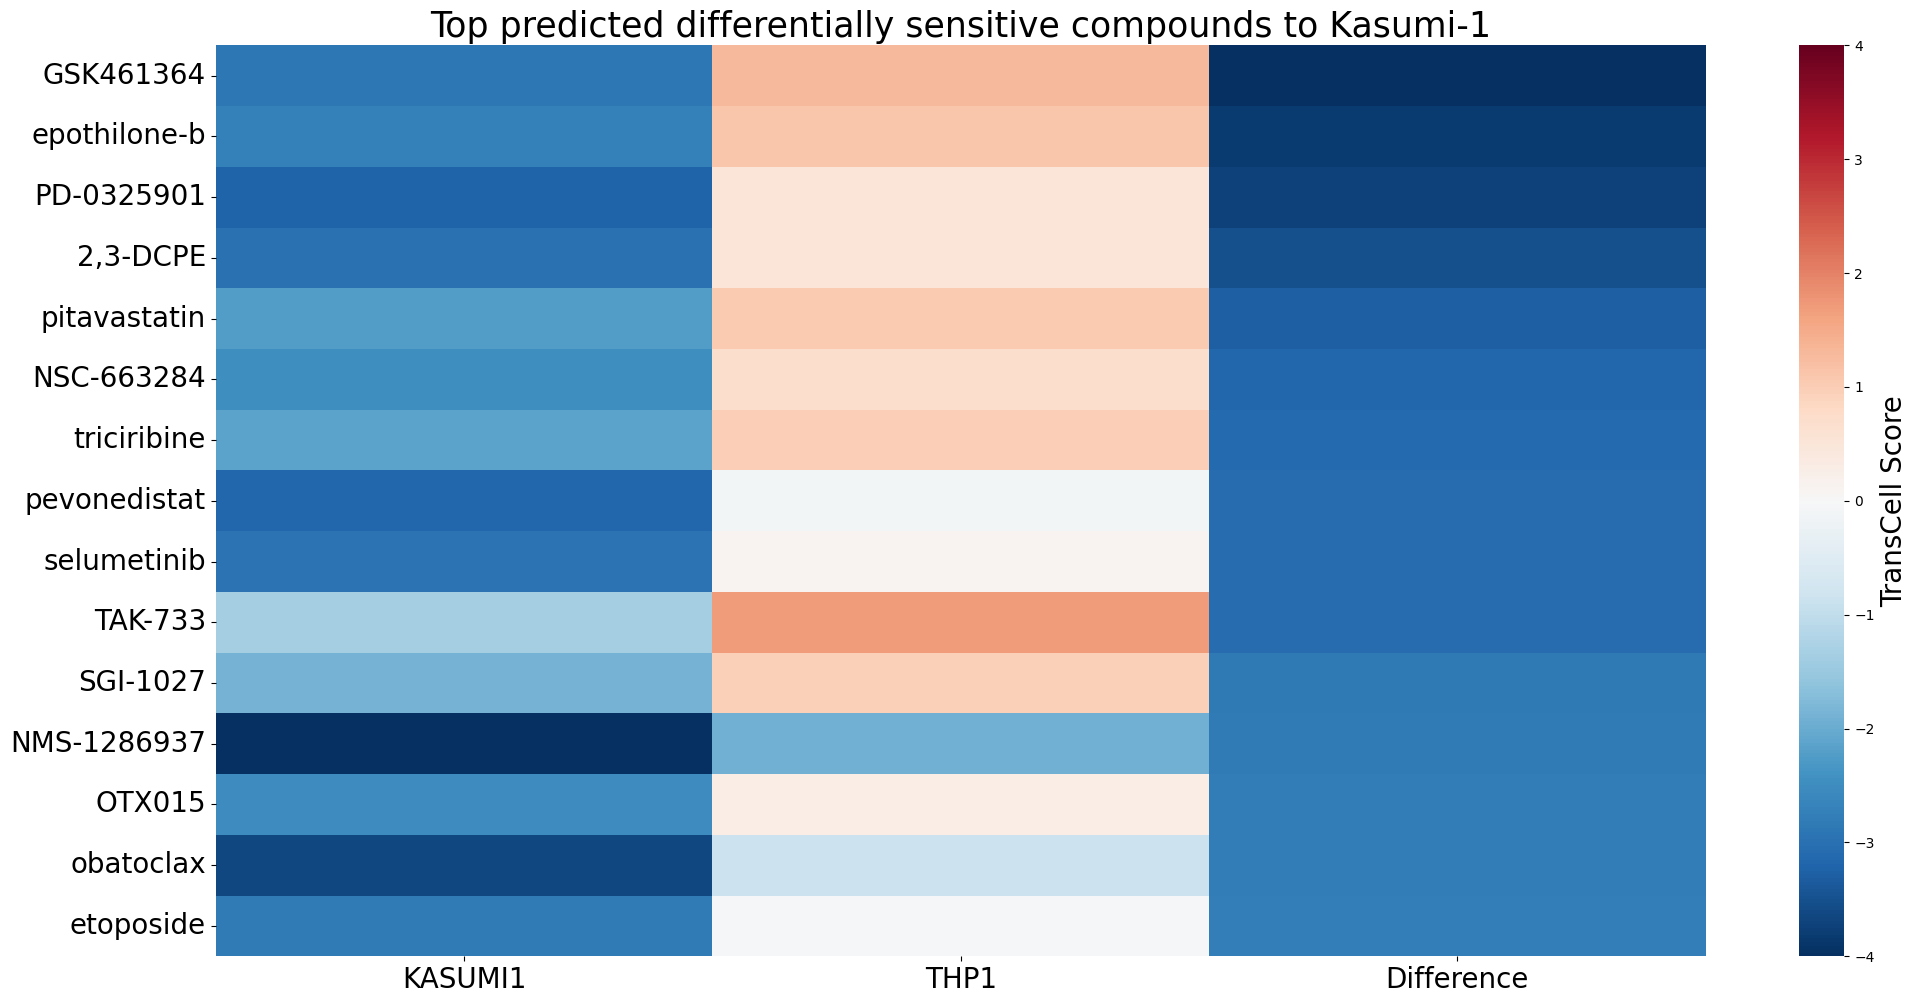

In [112]:
plt.figure(figsize=(20, 10))
kasumi_cand = kasumi_cand.sort_values('Diff').rename(columns={'Diff':'Difference'})
ax = sns.heatmap(kasumi_cand, cmap='RdBu_r', vmax=4, vmin=-4)
plt.title('Top predicted differentially sensitive compounds to Kasumi-1', fontsize=25)
plt.tight_layout()
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
cbar = ax.collections[0].colorbar
cbar.set_label('TransCell Score', fontsize=20)
plt.savefig(f"{FIGURE_DIR}/Fig_kasumi.pdf", format="pdf", bbox_inches="tight")
plt.show()

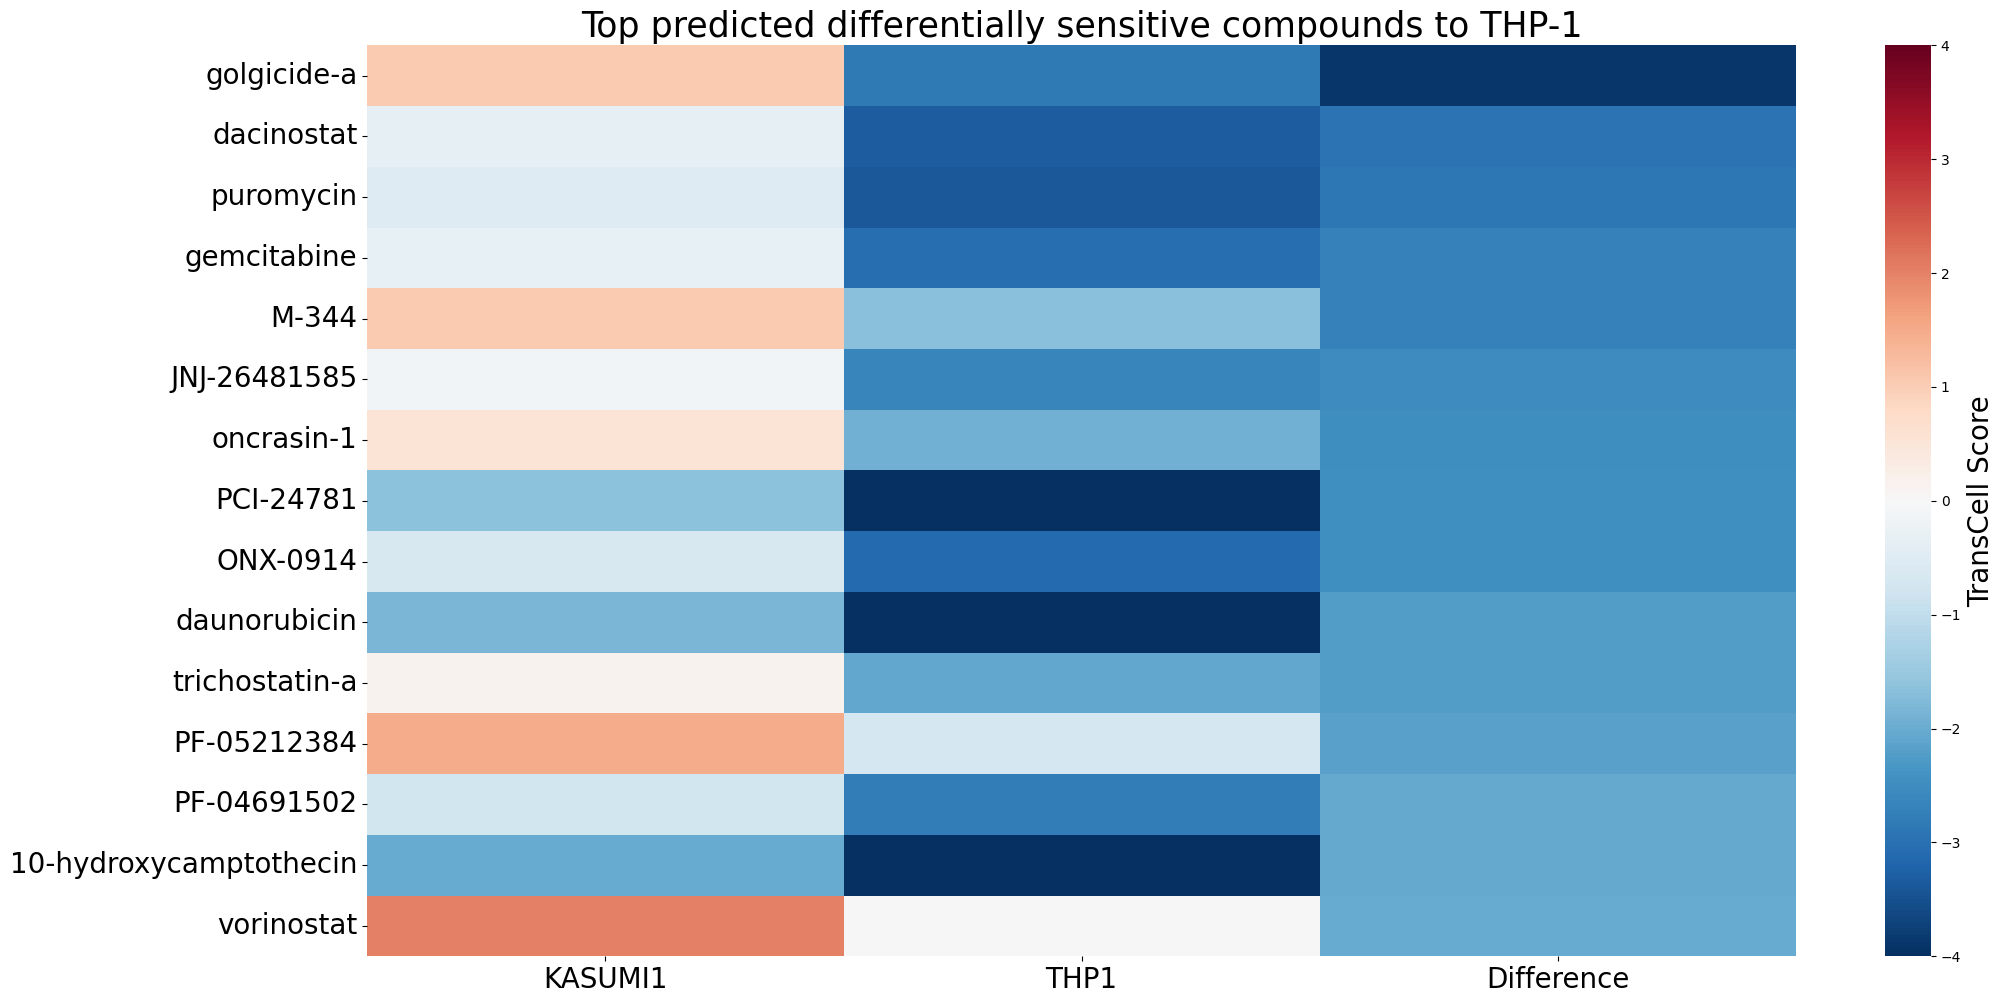

In [113]:
plt.figure(figsize=(20, 10))
thp1_cand = thp1_cand.sort_values('Diff').rename(columns={'Diff':'Difference'})
ax = sns.heatmap(thp1_cand, cmap='RdBu_r', vmax=4, vmin=-4)
plt.title('Top predicted differentially sensitive compounds to THP-1', fontsize=25)
plt.tight_layout()
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
cbar = ax.collections[0].colorbar
cbar.set_label('TransCell Score', fontsize=20)
plt.savefig(f"{FIGURE_DIR}/Fig_thp.pdf", format="pdf", bbox_inches="tight")
plt.show()